# 05-3. A3 기준 품질 노이즈 제거 ablation 실험

A-3을 공통 기준으로 두고, 길이·숫자 노이즈 후보를 train에서만 각각 독립적으로 제거한 A-4~A-8을 같은 KoBART 설정과 동일한 validation set으로 학습·평가한다. test는 이 노트북에서 사용하지 않는다.

- **A-4**: A-3에서 extreme_ratio 후보 제거
- **A-5**: A-3에서 summary_longer 후보 제거
- **A-6**: A-3에서 short_document 후보 제거
- **A-7**: A-3에서 short_and_summary_longer 교집합 후보만 제거
- **A-8**: A-3에서 숫자 불일치 후보 중 train 해당 행 제거

각 실험은 누적 방식이 아니라 A-3에서 독립적으로 시작한다. validation은 모든 실험에서 `processed_data/04-3_final/validation.csv`의 동일한 2,240행으로 고정한다. A3 기준 점수는 05-2의 `1e-5`, 512 결과를 재사용한다.


## 1. 설정

먼저 RUN_TRAINING=False로 데이터 구성, 제거 건수, validation 동일성, split 누수 검사를 확인한다. 이상이 없으면 True로 바꿔 실행한다. validation loss가 개선되지 않으면 early stopping하고, 최고 checkpoint에서 validation ROUGE를 계산한다.


In [1]:
import gc
import hashlib
import json
import os
import random
import re
import sys
import time
from pathlib import Path

PROJECT = Path(r"C:\Users\KDS-30\Desktop\Projects\06_Team_Project4")
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

RESULTS = PROJECT / "results" / "05-3_noise_ablation"
FINAL_DIR = PROJECT / "processed_data" / "04-3_final"
REVIEW_DIR = PROJECT / "review_data" / "04-4_final_quality_review"
A3_METRICS_PATH = (
    PROJECT / "results" / "05-2_hyperparameter_tuning"
    / "lr_1em05_len_512" / "validation_metrics.json"
)
RESULTS.mkdir(parents=True, exist_ok=True)

CANDIDATE_PATHS = {
    "A4": REVIEW_DIR / "03_extreme_ratio.csv",
    "A5": REVIEW_DIR / "04_summary_longer.csv",
    "A6": REVIEW_DIR / "05_short_document.csv",
    "A7": REVIEW_DIR / "06_short_and_summary_longer.csv",
    "A8": REVIEW_DIR / "07_number_mismatch.csv",
}

SEED = 42
MODEL_ID = "gogamza/kobart-base-v2"
MAX_SOURCE_LENGTH = 512
MAX_TARGET_LENGTH = 256
EPOCHS = 5
BATCH_SIZE = 2
LEARNING_RATE = 1e-5
EARLY_STOPPING_PATIENCE = 1
EARLY_STOPPING_MIN_DELTA = 0.0
EXPERIMENTS_TO_RUN = ["A4", "A5", "A6", "A7", "A8"]
RUN_TRAINING = True  # 데이터 검증 후 학습을 시작할 때만 True
SKIP_COMPLETED = True
SAVE_MODEL = True

print("Python:", sys.version.split()[0])
print("결과 폴더:", RESULTS)


Python: 3.11.9
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-3_noise_ablation


In [2]:
import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import HfApi
from torch import optim
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader, RandomSampler, SequentialSampler, TensorDataset
from transformers import AutoTokenizer, BartForConditionalGeneration

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "CUDA를 사용할 수 없습니다."
print("device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
VRAM(GB): 7.96


## 2. A-4~A-8 데이터 구성

모든 실험은 `processed_data/04-3_final`의 A3 train/validation에서 시작한다. 해당 실험의 후보 row_id는 train에서만 제거하고 validation은 완전히 고정한다. 따라서 각 실험의 차이는 train에 적용한 한 가지 추가 제거 규칙뿐이다.


In [3]:
required_paths = [
    FINAL_DIR / "train.csv",
    FINAL_DIR / "validation.csv",
    A3_METRICS_PATH,
    *CANDIDATE_PATHS.values(),
]
missing_paths = [str(path) for path in required_paths if not path.exists()]
assert not missing_paths, f"필요한 파일이 없습니다: {missing_paths}"

base_columns = ["row_id", "title", "document", "summary"]
a3 = {
    split: pd.read_csv(FINAL_DIR / f"{split}.csv")[base_columns].reset_index(drop=True)
    for split in ["train", "validation"]
}
for split, frame in a3.items():
    assert frame["row_id"].is_unique, f"A3 {split}: row_id 중복"

candidate_ids = {}
candidate_total_rows = {}
for experiment, path in CANDIDATE_PATHS.items():
    candidates = pd.read_csv(path, usecols=["row_id"])
    assert candidates["row_id"].is_unique, f"{path.name}: row_id 중복"
    candidate_ids[experiment] = set(candidates["row_id"])
    candidate_total_rows[experiment] = len(candidates)

common_validation = a3["validation"].copy()
experiment_frames = {}
removal_rows = []
for experiment, ids in candidate_ids.items():
    train = a3["train"].loc[~a3["train"]["row_id"].isin(ids)].reset_index(drop=True)
    experiment_frames[experiment] = {
        "train": train,
        "validation": common_validation.copy(),
    }
    removal_rows.append({
        "experiment": experiment,
        "candidate_file": CANDIDATE_PATHS[experiment].name,
        "candidate_rows_all_splits": candidate_total_rows[experiment],
        "removed_train_rows": len(a3["train"]) - len(train),
        "candidate_validation_rows_kept": int(common_validation["row_id"].isin(ids).sum()),
    })

experiment_labels = {
    "A4": "a3_remove_extreme_ratio",
    "A5": "a3_remove_summary_longer",
    "A6": "a3_remove_short_document",
    "A7": "a3_remove_short_and_summary_longer",
    "A8": "a3_remove_all_number_mismatch_candidates",
}

removal_counts = pd.DataFrame(removal_rows)
removal_counts.to_csv(RESULTS / "removal_counts.csv", index=False, encoding="utf-8-sig")

dataset_counts = pd.DataFrame([
    {
        "experiment": experiment,
        "description": experiment_labels[experiment],
        **{f"{split}_rows": len(frames[split]) for split in ["train", "validation"]},
    }
    for experiment, frames in experiment_frames.items()
])
dataset_counts.to_csv(RESULTS / "dataset_counts.csv", index=False, encoding="utf-8-sig")

overlap_matrix = pd.DataFrame(
    {
        right: {
            left: len(candidate_ids[left] & candidate_ids[right])
            for left in EXPERIMENTS_TO_RUN
        }
        for right in EXPERIMENTS_TO_RUN
    }
)
overlap_matrix.index.name = "experiment"
overlap_matrix.to_csv(RESULTS / "candidate_overlap_matrix.csv", encoding="utf-8-sig")

display(removal_counts)
display(dataset_counts)
display(overlap_matrix)


,experiment,candidate_file,candidate_rows_all_splits,removed_train_rows,candidate_validation_rows_kept
0,A4,03_extreme_ratio.csv,1024,756,115
1,A5,04_summary_longer.csv,610,450,71
2,A6,05_short_document.csv,486,368,51
3,A7,06_short_and_summary_longer.csv,414,314,46
4,A8,07_number_mismatch.csv,643,514,59


,experiment,description,train_rows,validation_rows
0,A4,a3_remove_extreme_ratio,18480,2240
1,A5,a3_remove_summary_longer,18786,2240
2,A6,a3_remove_short_document,18868,2240
3,A7,a3_remove_short_and_summary_longer,18922,2240
4,A8,a3_remove_all_number_mismatch_candidates,18722,2240


,A4,A5,A6,A7,A8
experiment,,,,,
A4,1024,610,470,414,50
A5,610,610,414,414,32
A6,470,414,486,414,24
A7,414,414,414,414,22
A8,50,32,24,22,643


In [4]:
space_pattern = re.compile(r"\s+")

def normalized_values(frame, column):
    return set(frame[column].astype(str).map(lambda value: space_pattern.sub(" ", value).strip()))

leakage_rows = []
common_validation_ids = common_validation["row_id"].tolist()
common_validation_digest = hashlib.sha256(
    "\n".join(common_validation_ids).encode("utf-8")
).hexdigest()

for experiment, frames in experiment_frames.items():
    assert frames["validation"]["row_id"].tolist() == common_validation_ids
    for split, frame in frames.items():
        assert frame["row_id"].is_unique, f"{experiment} {split}: row_id 중복"
        assert frame[["document", "summary"]].notna().all().all()
        assert frame["document"].astype(str).str.strip().ne("").all()
        assert frame["summary"].astype(str).str.strip().ne("").all()

    for column in ["document", "summary"]:
        train_values = normalized_values(frames["train"], column)
        validation_values = normalized_values(frames["validation"], column)
        leakage_rows.append({
            "experiment": experiment, "column": column,
            "left": "train", "right": "validation",
            "overlap": len(train_values & validation_values),
        })

leakage_check = pd.DataFrame(leakage_rows)
assert leakage_check["overlap"].sum() == 0, "split 간 document/summary 중복을 확인하세요."
leakage_check.to_csv(RESULTS / "split_leakage_check.csv", index=False, encoding="utf-8-sig")
display(leakage_check)
print("공통 validation 행 수:", len(common_validation))
print("공통 validation row_id SHA256:", common_validation_digest)
print("검증 통과: 모든 실험의 validation 동일, train-validation 중복 0, test 미사용")

,experiment,column,left,right,overlap
0,A4,document,train,validation,0
1,A4,summary,train,validation,0
2,A5,document,train,validation,0
3,A5,summary,train,validation,0
4,A6,document,train,validation,0
5,A6,summary,train,validation,0
6,A7,document,train,validation,0
7,A7,summary,train,validation,0
8,A8,document,train,validation,0
9,A8,summary,train,validation,0


공통 validation 행 수: 2240
공통 validation row_id SHA256: a8fbd4e4c551a61d4ef7ab3cfae85c701d385a3c2a8d81ea74cf3ec406af7a35
검증 통과: 모든 실험의 validation 동일, train-validation 중복 0, test 미사용


## 3. 공통 토큰화·학습·평가 함수

각 실험을 시작할 때 seed, 모델, optimizer를 새로 초기화한다. 따라서 이전 실험의 학습 상태가 다음 실험으로 전달되지 않는다.

In [5]:
model_revision = HfApi().model_info(MODEL_ID).sha
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=model_revision,
    clean_up_tokenization_spaces=False,
)
rouge_metric = evaluate.load("rouge")

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

def make_dataset(frame):
    source = tokenizer(
        text=frame["document"].astype(str).tolist(),
        padding="max_length", truncation=True, max_length=MAX_SOURCE_LENGTH,
        return_token_type_ids=False, return_tensors="pt",
    )
    target = tokenizer(
        text_target=frame["summary"].astype(str).tolist(),
        padding="max_length", truncation=True, max_length=MAX_TARGET_LENGTH,
        return_token_type_ids=False, return_tensors="pt",
    )
    labels = target["input_ids"].clone()
    labels[labels == tokenizer.pad_token_id] = -100
    return TensorDataset(source["input_ids"], source["attention_mask"], labels)

def make_loader(dataset, train_mode):
    sampler = RandomSampler(dataset) if train_mode else SequentialSampler(dataset)
    return DataLoader(dataset, sampler=sampler, batch_size=BATCH_SIZE, num_workers=0, pin_memory=True)

def train_one_epoch(model, optimizer, dataloader):
    model.train()
    total_loss = 0.0
    for step, batch in enumerate(dataloader, start=1):
        input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
        optimizer.zero_grad()
        loss = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss
        loss.backward()
        clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
        if step % 500 == 0:
            print(f"  step {step:,}/{len(dataloader):,} | loss {total_loss / step:.4f}")
    return total_loss / len(dataloader)

def evaluate_loss(model, dataloader):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for batch in dataloader:
            input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
            total_loss += model(
                input_ids=input_ids, attention_mask=attention_mask, labels=labels
            ).loss.item()
    return total_loss / len(dataloader)

def generate_predictions(model, dataloader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for step, batch in enumerate(dataloader, start=1):
            input_ids, attention_mask, _ = [tensor.to(device) for tensor in batch]
            generated_ids = model.generate(
                input_ids=input_ids, attention_mask=attention_mask,
                max_length=MAX_TARGET_LENGTH, num_beams=1, do_sample=False,
            )
            predictions.extend(tokenizer.batch_decode(
                generated_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False
            ))
            if step % 200 == 0:
                print(f"  generation {step:,}/{len(dataloader):,}")
    return [prediction.strip() for prediction in predictions]

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


## 4. A-4~A-8 순차 학습 및 공통 validation 평가

실험별 폴더에 best checkpoint, epoch loss, validation 예측, ROUGE 결과가 즉시 저장된다. validation loss가 EARLY_STOPPING_PATIENCE회 연속 개선되지 않으면 학습을 종료한다. SKIP_COMPLETED=True이면 validation_metrics.json이 존재하는 실험은 다시 학습하지 않는다. 마지막 표에는 05-2의 A3 기준 결과가 함께 들어간다.


[A4] 완료 결과가 있어 건너뜁니다.
[A5] 완료 결과가 있어 건너뜁니다.
[A6] 완료 결과가 있어 건너뜁니다.
[A7] 완료 결과가 있어 건너뜁니다.

===== A8: a3_remove_all_number_mismatch_candidates =====


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


train / validation: 18722 2240
  step 500/9,361 | loss 0.9310
  step 1,000/9,361 | loss 0.8319
  step 1,500/9,361 | loss 0.7702
  step 2,000/9,361 | loss 0.7328
  step 2,500/9,361 | loss 0.7088
  step 3,000/9,361 | loss 0.6894
  step 3,500/9,361 | loss 0.6720
  step 4,000/9,361 | loss 0.6581
  step 4,500/9,361 | loss 0.6469
  step 5,000/9,361 | loss 0.6374
  step 5,500/9,361 | loss 0.6293
  step 6,000/9,361 | loss 0.6221
  step 6,500/9,361 | loss 0.6150
  step 7,000/9,361 | loss 0.6085
  step 7,500/9,361 | loss 0.6034
  step 8,000/9,361 | loss 0.5976
  step 8,500/9,361 | loss 0.5938
  step 9,000/9,361 | loss 0.5902
A8 epoch 1/5 | train 0.5871 | validation 0.5047 | 27.6분
Saved: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-3_noise_ablation\A8\best_model_state.pt
  step 500/9,361 | loss 0.4199
  step 1,000/9,361 | loss 0.4257
  step 1,500/9,361 | loss 0.4295
  step 2,000/9,361 | loss 0.4252
  step 2,500/9,361 | loss 0.4275
  step 3,000/9,361 | loss 0.4267
  step 3,500/9,36

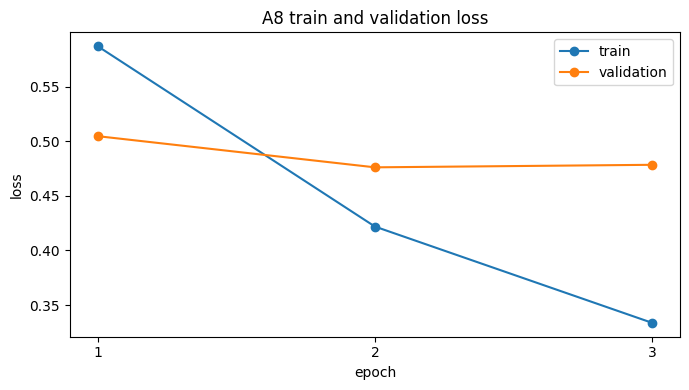

  generation 200/1,120
  generation 400/1,120
  generation 600/1,120
  generation 800/1,120
  generation 1,000/1,120


experiment                                                    A8
description             a3_remove_all_number_mismatch_candidates
train_rows                                                 18722
validation_rows                                             2240
removed_train_rows                                           514
epochs_ran                                                     3
best_epoch                                                     2
stopped_epoch                                                  3
best_validation_loss                                    0.476129
rouge1                                                 38.759065
rouge2                                                 32.333363
rougeL                                                 35.196486
rougeLsum                                              35.239697
Name: A8, dtype: object

,experiment,description,train_rows,validation_rows,removed_train_rows,epochs_ran,best_epoch,stopped_epoch,best_validation_loss,rouge1,rouge2,rougeL,rougeLsum,validation_rank
1,A4,a3_remove_extreme_ratio,18480,2240,756,4,3,4,0.477737,45.874813,38.483782,41.967754,41.977610,1
2,A5,a3_remove_summary_longer,18786,2240,450,4,3,4,0.473132,43.168150,35.970892,39.427803,39.428312,2
0,A3,automatic_clean_dedup_group_split_reference,19236,2240,0,3,2,3,0.468172,41.472195,34.688928,37.572240,37.579459,3
4,A7,a3_remove_short_and_summary_longer,18922,2240,314,4,3,4,0.481504,39.606101,33.077492,35.917317,36.034344,4
5,A8,a3_remove_all_number_mismatch_candidates,18722,2240,514,3,2,3,0.476129,38.759065,32.333363,35.196486,35.239697,5
3,A6,a3_remove_short_document,18868,2240,368,3,2,3,0.473784,35.510930,29.431607,32.370269,32.427130,6


In [6]:
a3_saved = json.loads(A3_METRICS_PATH.read_text(encoding="utf-8"))
assert float(a3_saved["learning_rate"]) == LEARNING_RATE
assert int(a3_saved["max_source_length"]) == MAX_SOURCE_LENGTH
assert int(a3_saved["effective_batch_size"]) == BATCH_SIZE
a3_baseline_metrics = {
    "experiment": "A3",
    "description": "automatic_clean_dedup_group_split_reference",
    "train_rows": len(a3["train"]),
    "validation_rows": len(a3["validation"]),
    "removed_train_rows": 0,
    "epochs_ran": int(a3_saved["epochs_ran"]),
    "best_epoch": int(a3_saved["best_epoch"]),
    "stopped_epoch": int(a3_saved["epochs_ran"]),
    "best_validation_loss": float(a3_saved["best_validation_loss"]),
    **{name: float(a3_saved[name]) for name in ["rouge1", "rouge2", "rougeL", "rougeLsum"]},
}
result_rows = [a3_baseline_metrics]

if RUN_TRAINING:
    for experiment in EXPERIMENTS_TO_RUN:
        assert experiment in experiment_frames, f"알 수 없는 실험: {experiment}"
        experiment_dir = RESULTS / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        metrics_path = experiment_dir / "validation_metrics.json"

        if SKIP_COMPLETED and metrics_path.exists():
            saved_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
            result_rows.append(saved_metrics)
            print(f"[{experiment}] 완료 결과가 있어 건너뜁니다.")
            continue

        print(f"\n===== {experiment}: {experiment_labels[experiment]} =====")
        reset_seed()
        frames = experiment_frames[experiment]
        train_dataset = make_dataset(frames["train"])
        validation_dataset = make_dataset(frames["validation"])
        train_loader = make_loader(train_dataset, train_mode=True)
        validation_loader = make_loader(validation_dataset, train_mode=False)
        print("train / validation:", len(train_dataset), len(validation_dataset))

        model = BartForConditionalGeneration.from_pretrained(
            MODEL_ID, revision=model_revision, use_safetensors=True
        ).to(device)
        optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, eps=1e-8)
        model_path = experiment_dir / "best_model_state.pt"
        best_validation_loss = float("inf")
        best_epoch = None
        stopped_epoch = None
        epochs_without_improvement = 0
        history = []

        for epoch in range(1, EPOCHS + 1):
            started = time.perf_counter()
            train_loss = train_one_epoch(model, optimizer, train_loader)
            validation_loss = evaluate_loss(model, validation_loader)
            elapsed_minutes = (time.perf_counter() - started) / 60
            history.append({
                "experiment": experiment,
                "epoch": epoch,
                "train_loss": train_loss,
                "validation_loss": validation_loss,
                "minutes": elapsed_minutes,
            })
            print(
                f"{experiment} epoch {epoch}/{EPOCHS} | train {train_loss:.4f} | "
                f"validation {validation_loss:.4f} | {elapsed_minutes:.1f}분"
            )

            improved = validation_loss < (best_validation_loss - EARLY_STOPPING_MIN_DELTA)
            if improved:
                best_validation_loss = validation_loss
                best_epoch = epoch
                epochs_without_improvement = 0
                torch.save(model.state_dict(), model_path)
                print("Saved:", model_path)
            else:
                epochs_without_improvement += 1
                print(
                    f"validation 미개선: {epochs_without_improvement}/"
                    f"{EARLY_STOPPING_PATIENCE}"
                )
                if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                    stopped_epoch = epoch
                    print(f"Early stopping: epoch {epoch}")
                    break

        history_df = pd.DataFrame(history)
        history_df.to_csv(experiment_dir / "loss_history.csv", index=False, encoding="utf-8-sig")
        plt.figure(figsize=(7, 4))
        plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="train")
        plt.plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="validation")
        plt.xlabel("epoch")
        plt.ylabel("loss")
        plt.title(f"{experiment} train and validation loss")
        plt.xticks(history_df["epoch"])
        plt.legend()
        plt.tight_layout()
        plt.savefig(experiment_dir / "loss_curve.png", dpi=160)
        plt.show()

        assert model_path.exists(), f"best checkpoint가 없습니다: {model_path}"
        model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
        predictions = generate_predictions(model, validation_loader)
        references = frames["validation"]["summary"].astype(str).tolist()
        rouge_scores = rouge_metric.compute(
            predictions=predictions,
            references=references,
            tokenizer=lambda text: text.split(),
            use_stemmer=False,
        )
        metrics = {
            "experiment": experiment,
            "description": experiment_labels[experiment],
            "train_rows": len(frames["train"]),
            "validation_rows": len(frames["validation"]),
            "removed_train_rows": len(a3["train"]) - len(frames["train"]),
            "epochs_ran": len(history_df),
            "best_epoch": best_epoch,
            "stopped_epoch": stopped_epoch,
            "best_validation_loss": best_validation_loss,
            **{name: score * 100 for name, score in rouge_scores.items()},
        }
        metrics_path.write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
        prediction_df = frames["validation"].copy()
        prediction_df["prediction"] = predictions
        prediction_df.to_csv(experiment_dir / "validation_predictions.csv", index=False, encoding="utf-8-sig")
        result_rows.append(metrics)
        display(pd.Series(metrics, name=experiment))

        if not SAVE_MODEL:
            model_path.unlink(missing_ok=True)
        del model, optimizer, train_dataset, validation_dataset
        del train_loader, validation_loader
        gc.collect()
        torch.cuda.empty_cache()

    experiment_results = pd.DataFrame(result_rows).sort_values("experiment").reset_index(drop=True)
    experiment_results["validation_rank"] = experiment_results["rougeL"].rank(
        method="min", ascending=False
    ).astype(int)
    experiment_results.to_csv(RESULTS / "experiment_results.csv", index=False, encoding="utf-8-sig")
    display(experiment_results.sort_values(["validation_rank", "best_validation_loss"]))
    best_row = experiment_results.sort_values(
        ["rougeL", "best_validation_loss"], ascending=[False, True]
    ).iloc[0].to_dict()
    (RESULTS / "best_validation_experiment.json").write_text(
        json.dumps(best_row, ensure_ascii=False, indent=2), encoding="utf-8"
    )
else:
    print("RUN_TRAINING=False: 데이터 구성과 누수 검사까지만 완료했습니다.")


In [7]:
run_config = {
    "model_id": MODEL_ID,
    "model_revision": model_revision,
    "seed": SEED,
    "max_source_length": MAX_SOURCE_LENGTH,
    "max_target_length": MAX_TARGET_LENGTH,
    "max_epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "early_stopping_min_delta": EARLY_STOPPING_MIN_DELTA,
    "experiments_to_run": EXPERIMENTS_TO_RUN,
    "experiment_labels": experiment_labels,
    "candidate_paths": {key: str(path) for key, path in CANDIDATE_PATHS.items()},
    "a3_reference_metrics_path": str(A3_METRICS_PATH),
    "candidate_removal_scope": "train_only",
    "common_validation_path": str(FINAL_DIR / "validation.csv"),
    "common_validation_rows": len(common_validation),
    "common_validation_row_id_sha256": common_validation_digest,
    "test_used": False,
    "generation": {"num_beams": 1, "do_sample": False},
}
(RESULTS / "run_config.json").write_text(
    json.dumps(run_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("저장 예정/완료 파일:")
for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))


저장 예정/완료 파일:
- results\05-3_noise_ablation\A4\best_model_state.pt
- results\05-3_noise_ablation\A4\loss_curve.png
- results\05-3_noise_ablation\A4\loss_history.csv
- results\05-3_noise_ablation\A4\validation_metrics.json
- results\05-3_noise_ablation\A4\validation_predictions.csv
- results\05-3_noise_ablation\A5\best_model_state.pt
- results\05-3_noise_ablation\A5\loss_curve.png
- results\05-3_noise_ablation\A5\loss_history.csv
- results\05-3_noise_ablation\A5\validation_metrics.json
- results\05-3_noise_ablation\A5\validation_predictions.csv
- results\05-3_noise_ablation\A6\best_model_state.pt
- results\05-3_noise_ablation\A6\loss_curve.png
- results\05-3_noise_ablation\A6\loss_history.csv
- results\05-3_noise_ablation\A6\validation_metrics.json
- results\05-3_noise_ablation\A6\validation_predictions.csv
- results\05-3_noise_ablation\A7\best_model_state.pt
- results\05-3_noise_ablation\A7\loss_curve.png
- results\05-3_noise_ablation\A7\loss_history.csv
- results\05-3_noise_ablation\A7